In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

# clock/03 — order id (oid)

**Hypothesis.** For each instruction the LM assigns an *order id* in the sequence
of appearance. At `b = ` the LM just looks up the instruction with order id 2
(1-indexed) and implements it. The question: **is the order id disentangled from
the instruction content?**

**Causal setup (cross-prompt interchange).** Source prompt has conditions
(s1, s2, s3); destination has (d1, d2, d3). Capture the latent at the source's
`c = ` (order id 3, content s3) and patch it into the destination's `b = `
(order id 2, content d2). Patch a consecutive **5-layer window** centered at `l`,
sweep `l` over `range(0, n_layer, step)`, for three latent types:
residual (`layer_name_format`), mlp (`mlp_module_name_format`),
attn (`attn_module_name_format`).

**Expectation (first generated token).**
- *Late layers*: the patch just copies the source's prediction → first token of **s3**.
- *Early–middle layers* (if order id is disentangled): the patched run emits the
  first token of **d3** (the destination's *own* 3rd condition) — the order id
  transports, the content does not.

Start with the **first generated token**; consecutive generation is a follow-up.

In [2]:
import os
import json
import logging

import numpy as np
import torch
from rich.console import Console
from rich.theme import Theme

from src.utils import env_utils, logging_utils

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4,5,6,7")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_SHORT = MODEL_NAME.split("/")[-1]
VERSION = "conditions"
CACHE_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", VERSION, MODEL_SHORT)

from src.models import ModelandTokenizer
mt = ModelandTokenizer(
    model_key=MODEL_NAME, dtype=torch.bfloat16, device_map="auto", attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"residual={mt.layer_name_format}  mlp={mt.mlp_module_name_format}  attn={mt.attn_module_name_format}")

2026-06-12 14:01:01 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-12 14:01:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-12 14:01:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-12 14:01:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-12 14:01:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-12 14:01:01 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-12 14:01:23 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-12 14:01:23 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-12 14:01:23 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40
residual=model.layers.{}  mlp=model.layers.{}.mlp  attn=model.layers.{}.self_attn


Let's go back for a bit to think about the order id again.
What we know: gaze heads, while implementing code for a instruction, look back to the token span specifying that instruction.
  
The gaze heads start getting deser after layer 40. Multiple activation patching experiments, spread around clock/05_verifier.ipynb, 13, 16, notebooks tell us that by layer 40/44 the LM has decided what to do and the rest of the layers just do it.

Question: **Who/where is that decision (what to do) being made?** Hypothesis: something needs to happen in the *earlier* layers.

In 03_oid.ipynb, we were looking for a order ID state. Which says that some state contains the information that *I am going to implement condition X*. We were patching full residual stream, and tracking for the first generated token. We didn't really find anything clean. 

Let's sharpen this up: 

Target: We have the gaze heads that look back to a specific instruction span. Which means, now we can calcualte a *collective gaze score*, per instruction span. We can use `ConditionSpec.id_substrs` for that. Instead of tracking the first generated token, this gives us a softer internal signal: *collective gaze score of the target instruction span*. 

Intervention: in 03_oid.ipynb we were patching full residual outputs. Let's try this instead: lets look for attention heads in < layer 40 that is able to increase the target signal: the collective gaze score of the target instruction span.
Approach: 
1) Patching the heads, one at a time, track the collective gaze score of gaze heads in > layer 40, and select the top k.
2) Learn a binary mask over the atteention heads in < layer 40. Objective: bringing over the output of the heads increases the target score. We selected the goalscope heads with a similar approach in scripts/train_head_mask.py. 

Check that I've made a copy of 03_oid.ipynb -> 03.1_oid_gaze.ipynb. Brainstorm with me on this direction. 
Ask me clarifications. Also, there are multiple design decisions to make before you start coding.

## 1. Build source / destination prefills

Source cut at `c = ` (order id 3), destination cut at `b = ` (order id 2). We also
cut the destination at `c = ` to read its *own* 3rd-condition first token (the
order-id-transported reference).

In [3]:
import re
from src.goals.multistep_label import LabeledGeneration


def load_labeled(sample_name, modularity="monolithic"):
    base = os.path.join(CACHE_ROOT, modularity, sample_name)
    with open(os.path.join(base, "labels.json")) as f:
        lab = LabeledGeneration.from_dict(json.load(f))
    with open(os.path.join(base, "completion.json")) as f:
        comp = json.load(f)
    return lab, comp


def cut_after_assignment(generation, var):
    m = re.search(rf"(?m)^\s*{re.escape(var)}\s*=", generation)
    if m is None:
        raise ValueError(f"no '{var} =' assignment line found")
    return m.end()


def build_prefill(sample_name, var, modularity="monolithic"):
    lab, comp = load_labeled(sample_name, modularity)
    cut = cut_after_assignment(lab.generation, var)
    return lab.full_prompt + lab.generation[:cut], lab


### ---- pick a source / destination pair (monolithic, ≥3 conditions) ----
SRC_SAMPLE = "cond_0053"     # provides the order-id-3 latent  (its `c =`)
DST_SAMPLE = "cond_0135"     # patched at its `b =` (order id 2)
### ----------------------------------------------------------------------
src_prefill, src_lab = build_prefill(SRC_SAMPLE, "c")     # s: order id 3
dst_prefill_b, dst_lab = build_prefill(DST_SAMPLE, "b")   # d: order id 2  (patch target)
dst_prefill_c, _ = build_prefill(DST_SAMPLE, "c")         # d: order id 3  (reference)

rich_print(f"[bold]SOURCE[/bold] {SRC_SAMPLE} — conditions:")
for i, sl in enumerate(src_lab.labels):
    rich_print(f"  s{i+1}: {sl.step_text}" + ("   ← captured @ `c =`" if i == 2 else ""))
rich_print(f"[bold]DEST[/bold]   {DST_SAMPLE} — conditions:")
for i, sl in enumerate(dst_lab.labels):
    tag = "   ← patched @ `b =`" if i == 1 else ("   ← order-id ref (d3)" if i == 2 else "")
    rich_print(f"  d{i+1}: {sl.step_text}{tag}")

SOURCE cond_0053 — conditions:

s1: n is odd

s2: n is less than or equal to 50

s3: n is a perfect square   ← captured @ `c =`

s4: the sum of n's digits is greater than 10

DEST   cond_0135 — conditions:

d1: n is divisible by 12

d2: n is odd   ← patched @ `b =`

d3: the sum of n's digits is greater than 5   ← order-id ref (d3)

d4: n is between 0 and 500 (inclusive)

d5: n is positive

In [4]:
print(src_prefill)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is odd
2. n is less than or equal to 50
3. n is a perfect square
4. the sum of n's digits is greater than 10

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any hel

In [5]:
print(dst_prefill_b)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is divisible by 12
2. n is odd
3. the sum of n's digits is greater than 5
4. n is between 0 and 500 (inclusive)
5. n is positive

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); d

In [6]:
from src.functional import generate_with_patch

test_prompt = dst_prefill_b
test_prompt = test_prompt.replace("b =", "c =")

test_gen = generate_with_patch(
    mt = mt,
    inputs = test_prompt,
    n_gen_per_prompt = 1,
    do_sample = True,
    max_new_tokens = 16,
    remove_prefix = True
)[0]

rich_print(f"[white]{test_prompt}[/white][sea_green1]{test_gen}[/sea_green1]")

You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is divisible by 12
2. n is odd
3. the sum of n's digits is greater than 5
4. n is between 0 and 500 (inclusive)
5. n is positive

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n % 12 == 0
    c = sum(int(digit) for digit in str(n)) > 5
   

In [7]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
goalscope_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(goalscope_heads)}")
print(f"  Selected heads: {goalscope_heads}")

_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in goalscope_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

In [8]:
from scripts.clock.score_condition_heads import load_head_scores

# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 100
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
gaze_heads = [(int(l), int(h)) for l, h in (np.unravel_index(i, gaze_scores.shape) for i in flat_idx)]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-100 gaze heads  (compare_with='mean', q_span=15)  score range [2.725, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 85 more)


In [9]:
from src.goals.goalscope import apply_goalscope

lab, comp = load_labeled(SRC_SAMPLE, modularity="monolithic")
prompt = comp["prompt"] + comp["generation"]
print(prompt)

res = apply_goalscope(
    prompt,
    mt=mt,
    selected_heads=sorted(goalscope_heads),
    # strategy="replace", alpha=1.0,
    strategy="additive", alpha=0.2,
    batch_size=32,
    # max_new_tokens=STEER_MAX_TOKENS,
    title="GoalScope"
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is odd
2. n is less than or equal to 50
3. n is a perfect square
4. the sum of n's digits is greater than 10

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any hel

GoalScope[additive]:   0%|          | 0/4 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


## 1b. Filter non-collision pairs (from cache, no model forward)

The cached generations are greedy decodes, so the first token after `var = ` is
already in the data — tokenize `full_prompt + generation` and read the token at
the cut boundary. For a pair (src, dst) the three references are
`s3 = src@c`, `d2 = dst@b`, `d3 = dst@c`; we keep pairs where all three differ
(and `dst@b ≠ dst@c`).

In [10]:
import random

dec = lambda t: mt.tokenizer.decode([t])


def list_monolithic_samples():
    d = os.path.join(CACHE_ROOT, "monolithic")
    return sorted(x for x in os.listdir(d) if os.path.isdir(os.path.join(d, x)))


def first_gen_token_after(lab, var):
    """The cached greedy token immediately after `var = ` (token id), or None."""
    cut = cut_after_assignment(lab.generation, var)         # raises if no `var =` line
    combined = lab.full_prompt + lab.generation
    pref_len = len(lab.full_prompt) + cut
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    for tid, (a, b) in zip(enc["input_ids"], enc["offset_mapping"]):
        if a >= pref_len and b > a:
            return tid
    return None


def sample_oid_tokens(sample):
    lab, _ = load_labeled(sample, "monolithic")
    if len(lab.labels) < 3:
        return None
    try:
        tb, tc = first_gen_token_after(lab, "b"), first_gen_token_after(lab, "c")
    except ValueError:
        return None
    if tb is None or tc is None:
        return None
    return dict(sample=sample, tb=tb, tc=tc, lab=lab)


def find_noncollision_pairs(n_pairs=6, limit=150, seed=0):
    info = [x for x in (sample_oid_tokens(s) for s in list_monolithic_samples()[:limit]) if x]
    rng = random.Random(seed)
    rng.shuffle(info)
    pairs = []
    for dst in info:
        if dst["tb"] == dst["tc"]:                          # need d2 != d3
            continue
        for src in info:
            if src["sample"] == dst["sample"]:
                continue
            if len({src["tc"], dst["tb"], dst["tc"]}) == 3:
                pairs.append((src, dst))
                break
        if len(pairs) >= n_pairs:
            break
    return pairs


for src, dst in find_noncollision_pairs(n_pairs=6):
    s3, d2, d3 = src["tc"], dst["tb"], dst["tc"]
    rich_print(f"[bold]SRC={src['sample']}  DST={dst['sample']}[/bold]   "
               f"s3={dec(s3)!r}  d2={dec(d2)!r}  d3={dec(d3)!r}")
    rich_print(f"    s3: {src['lab'].labels[2].step_text}")
    rich_print(f"    d2: {dst['lab'].labels[1].step_text}    d3: {dst['lab'].labels[2].step_text}")

SRC=cond_0053  DST=cond_0050   s3=' int'  d2=' str'  d3=' n'

s3: n is a perfect square

d2: n is a palindrome (its digits read the same forwards and backwards)    d3: n is less than or equal to 500

SRC=cond_0123  DST=cond_0053   s3=' '  d2=' n'  d3=' int'

s3: n is between 0 and 500 (inclusive)

d2: n is less than or equal to 50    d3: n is a perfect square

... (8 outputs left out)

d2: n is odd    d3: the sum of n's digits is greater than 5

SRC=cond_0053  DST=cond_0119   s3=' int'  d2=' n'  d3=' str'

s3: n is a perfect square

d2: n is odd    d3: n is a palindrome (its digits read the same forwards and backwards)

## 2. Reference first tokens + distinctness

The patched first token is compared against three references; the experiment is
only legible if they are **distinct**.

In [11]:
from src.tokens import prepare_input
from src.functional import get_module_nnsight


@torch.no_grad()
def _trace_logits(prompt, name_format=None, patch_map=None, pos=-1):
    """One forward. Optionally REPLACE the module output at `pos` with each latent in
    patch_map (layer→vector). Returns next-token logits (vocab,) on CPU."""
    inp = prepare_input(prompts=[prompt], tokenizer=mt, add_special_tokens=False)
    with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                  scan=False, validate=False):
        if patch_map:
            for l in sorted(patch_map):                       # ascending = execution order
                name = name_format.format(l)
                mod = get_module_nnsight(mt, name)
                state = mod.output[0] if "attn" in name else mod.output
                state[:, pos, :] = patch_map[l].to(device=state.device, dtype=state.dtype)
        logits = mt.output.logits[:, -1, :].save()
    return logits[0].detach().float().cpu()


def top1(prompt):
    lg = _trace_logits(prompt)
    return int(lg.argmax()), lg


t_s3, _ = top1(src_prefill)       # source's own 3rd-cond first token  (content copy)
t_d2, _ = top1(dst_prefill_b)     # dest order-2 first token           (no effect)
t_d3, _ = top1(dst_prefill_c)     # dest order-3 first token           (oid transported)

dec = lambda t: mt.tokenizer.decode([t])
rich_print(f"t_s3 (content/copy)      = {dec(t_s3)!r}  (id {t_s3})")
rich_print(f"t_d2 (no effect)         = {dec(t_d2)!r}  (id {t_d2})")
rich_print(f"t_d3 (oid transported)   = {dec(t_d3)!r}  (id {t_d3})")
if len({t_s3, t_d2, t_d3}) < 3:
    rich_print("[bold red]⚠ references collide — pick a different SRC/DST pair so s3/d2/d3 first tokens differ[/]")
else:
    rich_print("[green]✓ three references are distinct[/]")

t_s3 (content/copy)      = ' int'  (id 526)

t_d2 (no effect)         = ' n'  (id 308)

t_d3 (oid transported)   = ' sum'  (id 2629)

✓ three references are distinct

## 3. Capture + windowed patch + layer sweep

Capture all source latents at its `c = ` position (one forward), then for each
center `l` patch the 5-layer window into the destination's `b = ` and read the
next-token distribution.

In [12]:
@torch.no_grad()
def capture_latents(prompt, name_format, pos=-1):
    """All per-layer module outputs at `pos`, one forward. Returns {layer: (n_embd,) cpu}."""
    inp = prepare_input(prompts=[prompt], tokenizer=mt, add_special_tokens=False)
    saved = {}
    with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                  scan=False, validate=False):
        for l in range(mt.n_layer):
            name = name_format.format(l)
            mod = get_module_nnsight(mt, name)
            state = mod.output[0] if "attn" in name else mod.output
            saved[l] = state[:, pos, :].save()
    return {l: v.detach()[0].float().cpu() for l, v in saved.items()}


def run_sweep(name_format, src_prefill, dst_prefill, refs, centers, half=2):
    """Patch a (2*half+1)-layer window of source latents into dst@`b =`; sweep center."""
    src_lat = capture_latents(src_prefill, name_format)
    rows = []
    for c in centers:
        win = [l for l in range(c - half, c + half + 1) if 0 <= l < mt.n_layer]
        lg = _trace_logits(dst_prefill, name_format, {l: src_lat[l] for l in win})
        # p = lg.softmax(-1)
        p = lg
        rows.append(dict(center=c, argmax=int(lg.argmax()),
                         p_d2=float(p[refs["d2"]]), p_d3=float(p[refs["d3"]]), p_s3=float(p[refs["s3"]])))
    return rows


STEP = 2
WINDOW_HALF = 2                              # 5-layer window
centers = list(range(0, mt.n_layer, STEP))
refs = {"s3": t_s3, "d2": t_d2, "d3": t_d3}

MODULES = [("residual", mt.layer_name_format),
           ("mlp",      mt.mlp_module_name_format),
           ("attn",     mt.attn_module_name_format)]

sweeps = {}
for mod_name, fmt in MODULES:
    rich_print(f"[cyan]sweeping {mod_name} …[/]")
    sweeps[mod_name] = run_sweep(fmt, src_prefill, dst_prefill_b, refs, centers, WINDOW_HALF)

sweeping residual …

sweeping mlp …

sweeping attn …

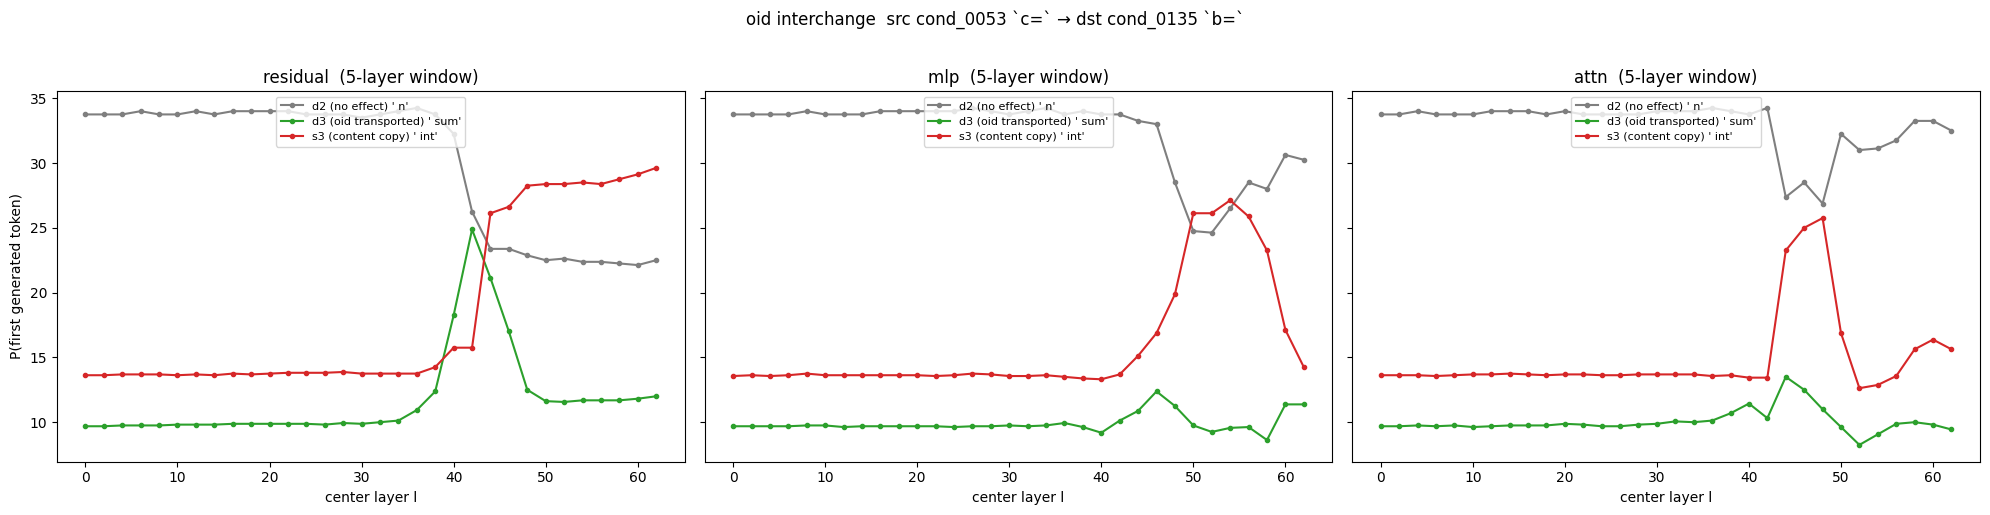

residual — argmax first token by center layer:
  l= 0: ' n'           [d2]
  l= 2: ' n'           [d2]
  l= 4: ' n'           [d2]
  l= 6: ' n'           [d2]
  l= 8: ' n'           [d2]
  l=10: ' n'           [d2]
  l=12: ' n'           [d2]
  l=14: ' n'           [d2]
  l=16: ' n'           [d2]
  l=18: ' n'           [d2]
  l=20: ' n'           [d2]
  l=22: ' n'           [d2]
  l=24: ' n'           [d2]
  l=26: ' n'           [d2]
  l=28: ' n'           [d2]
  l=30: ' n'           [d2]
  l=32: ' n'           [d2]
  l=34: ' n'           [d2]
  l=36: ' n'           [d2]
  l=38: ' n'           [d2]
  l=40: ' n'           [d2]
  l=42: ' n'           [d2]
  l=44: ' int'         [s3]
  l=46: ' int'         [s3]
  l=48: ' int'         [s3]
  l=50: ' int'         [s3]
  l=52: ' int'         [s3]
  l=54: ' int'         [s3]
  l=56: ' int'         [s3]
  l=58: ' int'         [s3]
  l=60: ' int'         [s3]
  l=62: ' int'         [s3]


In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, (mod_name, _) in zip(axes, MODULES):
    rows = sweeps[mod_name]
    cs = [r["center"] for r in rows]
    ax.plot(cs, [r["p_d2"] for r in rows], "-o", ms=3, label=f"d2 (no effect) {dec(t_d2)!r}", color="tab:gray")
    ax.plot(cs, [r["p_d3"] for r in rows], "-o", ms=3, label=f"d3 (oid transported) {dec(t_d3)!r}", color="tab:green")
    ax.plot(cs, [r["p_s3"] for r in rows], "-o", ms=3, label=f"s3 (content copy) {dec(t_s3)!r}", color="tab:red")
    ax.set_title(f"{mod_name}  (5-layer window)")
    ax.set_xlabel("center layer l")
    ax.legend(fontsize=8, loc="upper center")
axes[0].set_ylabel("P(first generated token)")
fig.suptitle(f"oid interchange  src {SRC_SAMPLE} `c=` → dst {DST_SAMPLE} `b=`", y=1.02)
plt.tight_layout()
plt.show()

# argmax token per center (residual), to eyeball the transition
print("residual — argmax first token by center layer:")
for r in sweeps["residual"]:
    which = {t_d2: "d2", t_d3: "d3", t_s3: "s3"}.get(r["argmax"], "·")
    print(f"  l={r['center']:2d}: {dec(r['argmax'])!r:14s} [{which}]")

In [14]:
# follow-up: consecutive generation with the patch held (see src.functional.generate_with_patch)

## 3 (cont.) — aggregate over all valid pairs

Run the same windowed interchange (`src @ c` → `dst @ b`) over every non-collision pair from §1b. Raw logits aren't comparable across pairs, so we aggregate by **argmax classification**: at each center layer, the fraction of pairs whose patched first token equals `d3` (oid transported), `d2` (no effect), `s3` (content copy), or something else.

In [15]:
from collections import defaultdict
from tqdm.auto import tqdm

N_PAIRS    = 50
LIMIT_SCAN = 200
multi_pairs = find_noncollision_pairs(n_pairs=N_PAIRS, limit=LIMIT_SCAN, seed=0)
print(f"{len(multi_pairs)} valid (src, dst) pairs")

REFS3 = ("d2", "d3", "s3")

def _classify(am, r):
    return ("d3" if am == r["d3"] else "d2" if am == r["d2"]
            else "s3" if am == r["s3"] else "other")

nC = len(centers)
multi_counts = {m: {c: defaultdict(int) for c in centers} for m, _ in MODULES}
# softer per-pair metrics: (n_pairs, n_centers) arrays, per module per ref
multi_logit = {m: {k: np.full((len(multi_pairs), nC), np.nan) for k in REFS3} for m, _ in MODULES}
multi_prob  = {m: {k: np.full((len(multi_pairs), nC), np.nan) for k in REFS3} for m, _ in MODULES}

for pi, (src, dst) in enumerate(tqdm(multi_pairs)):
    sp = build_prefill(src["sample"], "c")[0]
    dp = build_prefill(dst["sample"], "b")[0]
    r  = {"s3": src["tc"], "d2": dst["tb"], "d3": dst["tc"]}   # cached greedy tokens
    for mod_name, fmt in MODULES:
        src_lat = capture_latents(sp, fmt)
        for ci, c in enumerate(centers):
            win = [l for l in range(c - WINDOW_HALF, c + WINDOW_HALF + 1) if 0 <= l < mt.n_layer]
            lg = _trace_logits(dp, fmt, {l: src_lat[l] for l in win})
            prob = lg.softmax(-1)
            multi_counts[mod_name][c][_classify(int(lg.argmax()), r)] += 1
            for k in REFS3:
                multi_logit[mod_name][k][pi, ci] = float(lg[r[k]])
                multi_prob[mod_name][k][pi, ci]  = float(prob[r[k]])

50 valid (src, dst) pairs


  0%|          | 0/50 [00:00<?, ?it/s]

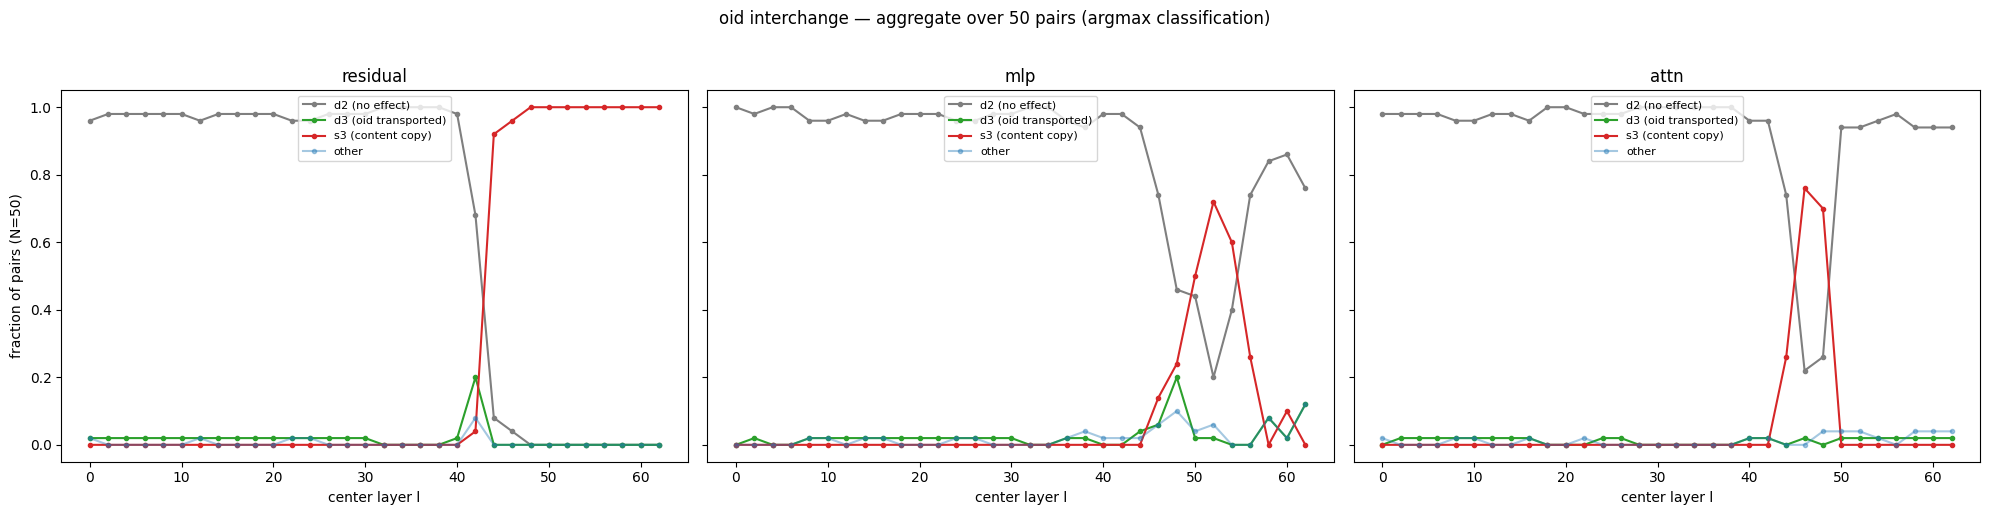

In [16]:
N = len(multi_pairs)
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, (mod_name, _) in zip(axes, MODULES):
    frac = lambda key: [multi_counts[mod_name][c][key] / N for c in centers]
    ax.plot(centers, frac("d2"),    "-o", ms=3, color="tab:gray",  label="d2 (no effect)")
    ax.plot(centers, frac("d3"),    "-o", ms=3, color="tab:green", label="d3 (oid transported)")
    ax.plot(centers, frac("s3"),    "-o", ms=3, color="tab:red",   label="s3 (content copy)")
    ax.plot(centers, frac("other"), "-o", ms=3, color="tab:blue", alpha=0.4, label="other")
    ax.set_title(mod_name)
    ax.set_xlabel("center layer l")
    ax.legend(fontsize=8, loc="upper center")
axes[0].set_ylabel(f"fraction of pairs (N={N})")
fig.suptitle(f"oid interchange — aggregate over {N} pairs (argmax classification)", y=1.02)
plt.tight_layout()
plt.show()

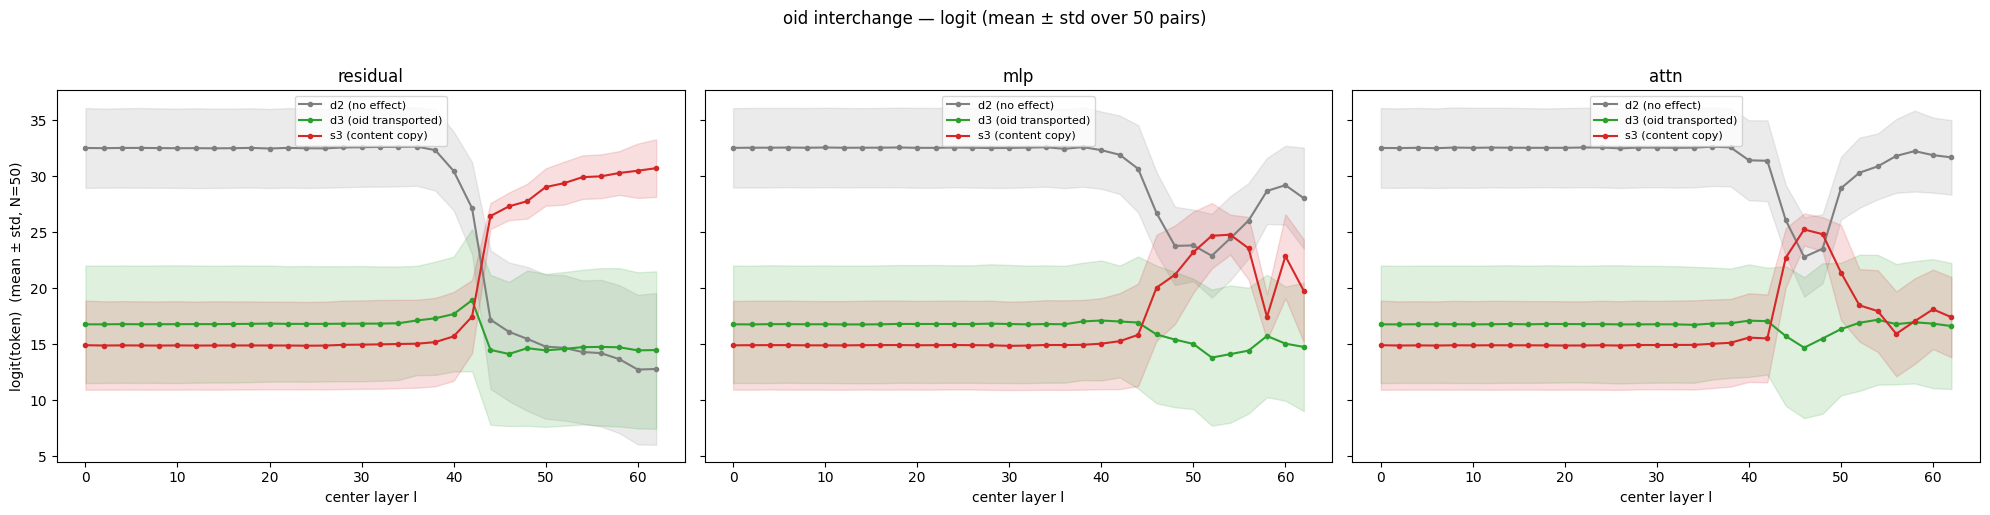

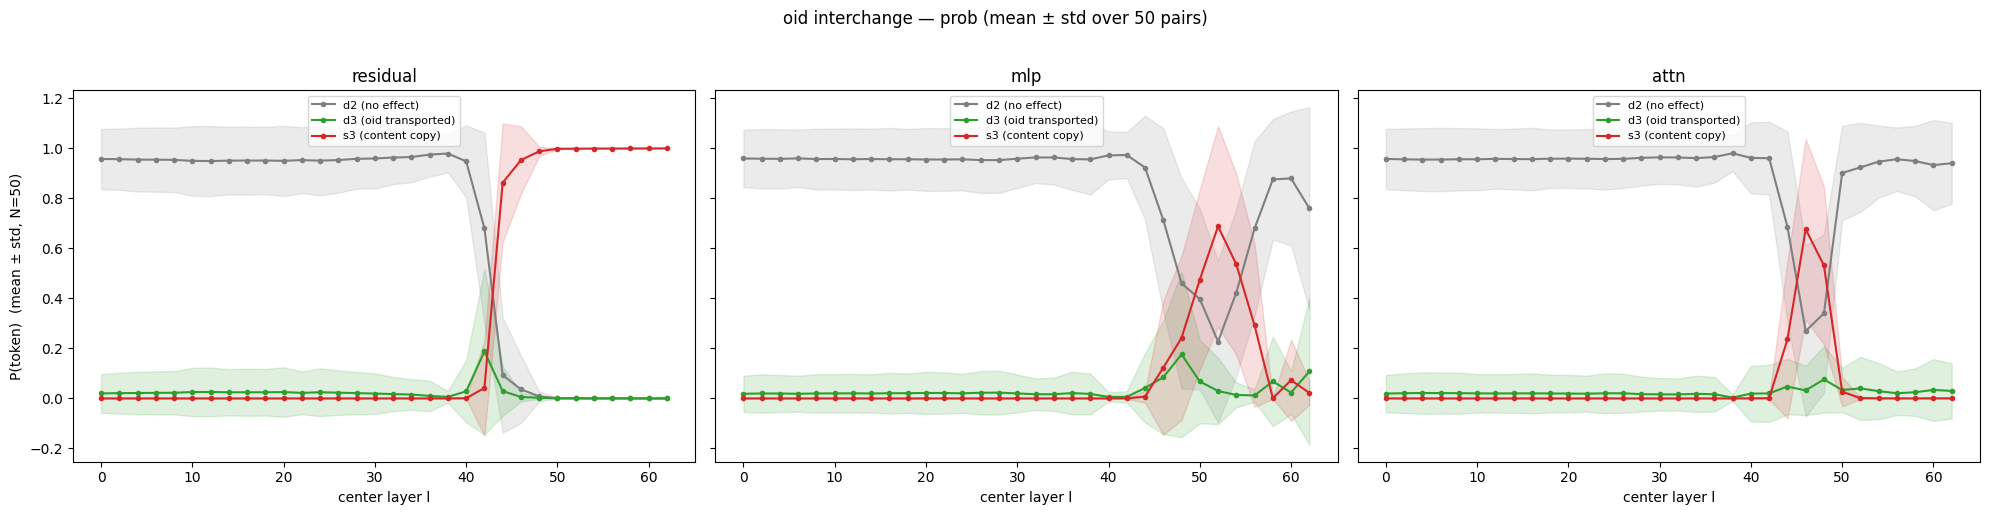

In [17]:
# softer metrics: logit and prob, mean ± std (error bars) over pairs
LABELS3 = {
    "d2": "d2 (no effect)",
    "d3": "d3 (oid transported)",
    "s3": "s3 (content copy)",
}
COL3 = {"d2": "tab:gray", "d3": "tab:green", "s3": "tab:red"}
_ms = lambda a: (np.nanmean(a, axis=0), np.nanstd(a, axis=0))

for metric, store, ylab in [
    ("logit", multi_logit, "logit(token)"),
    ("prob", multi_prob, "P(token)"),
]:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
    for ax, (mod_name, _) in zip(axes, MODULES):
        for k in REFS3:
            m, sd = _ms(store[mod_name][k])
            ax.plot(centers, m, "-o", ms=3, color=COL3[k], label=LABELS3[k])
            ax.fill_between(centers, m - sd, m + sd, color=COL3[k], alpha=0.15)
        ax.set_title(mod_name)
        ax.set_xlabel("center layer l")
        ax.legend(fontsize=8, loc="upper center")
    axes[0].set_ylabel(f"{ylab}  (mean ± std, N={len(multi_pairs)})")
    fig.suptitle(
        f"oid interchange — {metric} (mean ± std over {len(multi_pairs)} pairs)", y=1.02
    )
    plt.tight_layout()
    plt.show()

## §A · Step-0 diagnostic — does the gaze fire *at the pivot token*?

Before intervening, verify the readout locus is viable. For each condition *k* we read the **>L40 gaze heads'** attention from query `pivot+δ` into every condition's `id_substrs` span, and ask whether — at **δ=0 (the pivot)** — the *target* span *k* is already the one attended to.

- **target-span share** = `gaze(→span_k) / Σ_{k'} gaze(→span_{k'})` (1/n_cond = chance).
- **argmax-hit** = is span *k* the most-gazed-at span.

Pure-numpy over the **cached** `attn.npz` (no model forward). If the pivot row is already diagonal-dominant, the *intervene-at-pivot / read-at-pivot* loop closes; if the signal only switches on a few tokens into the code, we revisit the locus. We also overlay the **L≤40 gaze heads** and **all heads** to confirm the pivot-gaze is specific to the late gaze heads.

readout sets: {'gaze L>40': 254, 'gaze L≤40': 96, 'all heads': 2560}
scanning 50 cached monolithic samples
  10/50
  20/50
  30/50
  40/50
  50/50
chance share ≈ 0.249  (mean 1/n_keyed)


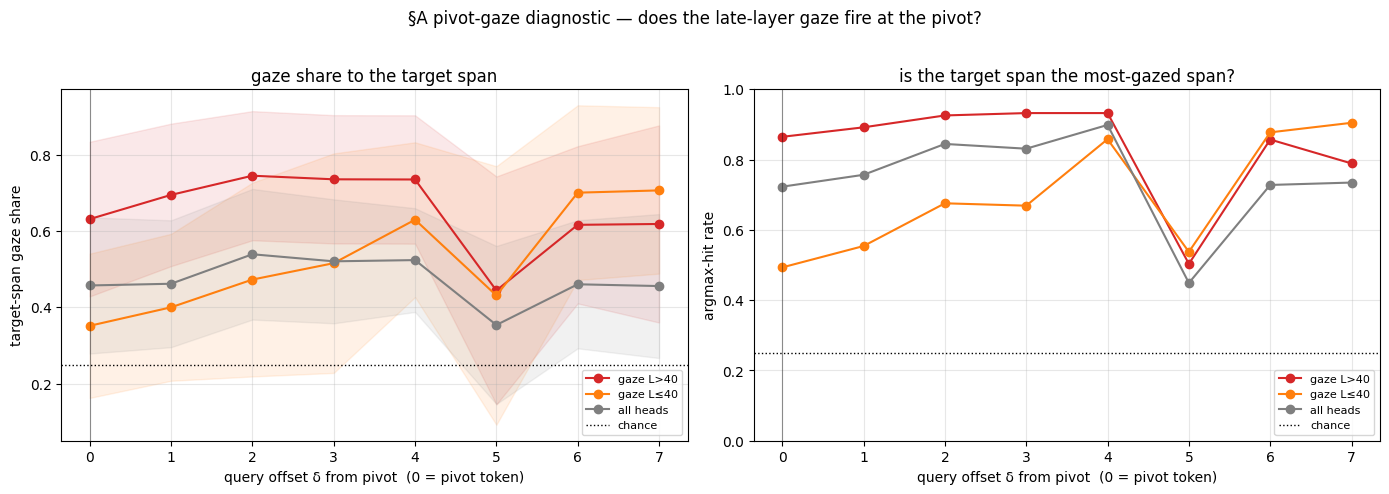


PIVOT (δ=0), gaze L>40:  share=0.632  argmax-hit=0.865   (chance 0.249)


In [18]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
from scripts.clock.score_condition_heads import load_head_scores

### ---- diagnostic config ----
Q_SPAN_SCORE   = 15
COMPARE_WITH   = "mean"          # which cached head-score config to load the gaze set from
TOP_N          = 350             # gaze set = top-N heads on the 'combined' lookback ratio (matches nb02)
WHICH_SCORE    = "combined"
LAYER_BOUNDARY = 40              # readout gaze heads must be in layers > LAYER_BOUNDARY
OFFSETS        = list(range(0, 8))   # query offset δ from the pivot (0 = pivot token)
MODULARITY     = "monolithic"
SKIP_LAST_MONO = True            # mirror score_condition_heads (last 'step' is print+rest)
N_SAMPLES      = 50              # cap (each cached attn is ~GB); raise for tighter error bars
### ---------------------------

def _select_topk(score, top_n):
    flat = np.argsort(score, axis=None)[::-1][:top_n]
    return [(int(l), int(h)) for l, h in (np.unravel_index(i, score.shape) for i in flat)]

_hs = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN_SCORE, compare_with=COMPARE_WITH)
_score = _hs[WHICH_SCORE]
gaze_all = _select_topk(_score, TOP_N)
READOUT_SETS = {
    f"gaze L>{LAYER_BOUNDARY}": [(l, h) for (l, h) in gaze_all if l >  LAYER_BOUNDARY],
    f"gaze L\u2264{LAYER_BOUNDARY}": [(l, h) for (l, h) in gaze_all if l <= LAYER_BOUNDARY],
    "all heads":               [(l, h) for l in range(_score.shape[0]) for h in range(_score.shape[1])],
}
print("readout sets:", {k: len(v) for k, v in READOUT_SETS.items()})
LH = {rs: (np.array([l for l, _ in v]), np.array([h for _, h in v]))
      for rs, v in READOUT_SETS.items() if v}

def _key_idx(step_ranges, seq):
    idx = set()
    for r in step_ranges:
        if r:
            idx.update(t for t in range(int(r[0]), int(r[1])) if 0 <= t < seq)
    return np.array(sorted(idx), dtype=np.int64)

_mono_dir = os.path.join(CACHE_ROOT, MODULARITY)
_attn_dir = os.path.join(CACHE_ROOT, "attn", MODULARITY)
samples = sorted(s for s in os.listdir(_mono_dir)
                 if os.path.exists(os.path.join(_attn_dir, s, "attn.npz"))
                 and os.path.exists(os.path.join(_mono_dir, s, "key_ranges.json")))[:N_SAMPLES]
print(f"scanning {len(samples)} cached {MODULARITY} samples")

share = {rs: {d: [] for d in OFFSETS} for rs in LH}     # target-span gaze share
hit   = {rs: {d: [] for d in OFFSETS} for rs in LH}     # is target span the argmax
chance = []                                             # 1/n_keyed per target (chance share & hit)

for si, s in enumerate(samples):
    attn = np.load(os.path.join(_attn_dir, s, "attn.npz"), allow_pickle=True)["attn"]  # (L,H,seq,seq) f16
    seq = attn.shape[-1]
    labels = json.load(open(os.path.join(_mono_dir, s, "labels.json")))["labels"]
    kr = json.load(open(os.path.join(_mono_dir, s, "key_ranges.json")))["step_key_token_ranges"]
    n = min(len(labels), len(kr))
    kidx = {i: _key_idx(kr[i], seq) for i in range(n)}
    keyed = [i for i in range(n) if kidx[i].size > 0]
    if len(keyed) < 2:
        del attn; continue
    targets = [i for i in range(n) if labels[i].get("gen_token_range") and kidx[i].size > 0]
    if SKIP_LAST_MONO and MODULARITY == "monolithic":
        targets = [i for i in targets if i != len(labels) - 1]
    for k in targets:
        q0, q1 = labels[k]["gen_token_range"]
        chance.append(1.0 / len(keyed))
        ki_pos = keyed.index(k)
        for d in OFFSETS:
            q = q0 + d
            if q >= q1 or q >= seq:
                continue
            for rs, (Ls, Hs) in LH.items():
                col = attn[Ls, Hs, q, :].astype(np.float32)            # (|set|, seq)
                sc = np.array([col[:, kidx[i]].mean() for i in keyed]) # gaze to each keyed span
                tot = sc.sum()
                share[rs][d].append(sc[ki_pos] / tot if tot > 0 else np.nan)
                hit[rs][d].append(bool(sc.argmax() == ki_pos))
    del attn
    if (si + 1) % 10 == 0:
        print(f"  {si + 1}/{len(samples)}")

chance_share = float(np.mean(chance))
print(f"chance share \u2248 {chance_share:.3f}  (mean 1/n_keyed)")

# ---- plot: target-span share & argmax-hit vs query offset δ ----
COLORS = {list(LH)[0]: "tab:red", list(LH)[1]: "tab:orange", "all heads": "tab:gray"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for rs in LH:
    ms = np.array([np.nanmean(share[rs][d]) if share[rs][d] else np.nan for d in OFFSETS])
    ss = np.array([np.nanstd(share[rs][d]) if share[rs][d] else np.nan for d in OFFSETS])
    mh = np.array([np.mean(hit[rs][d]) if hit[rs][d] else np.nan for d in OFFSETS])
    c = COLORS.get(rs, None)
    axes[0].plot(OFFSETS, ms, "o-", color=c, label=rs)
    axes[0].fill_between(OFFSETS, ms - ss, ms + ss, color=c, alpha=0.1)
    axes[1].plot(OFFSETS, mh, "o-", color=c, label=rs)
axes[0].axhline(chance_share, color="k", ls=":", lw=1, label="chance")
axes[0].axvline(0, color="k", lw=0.8, alpha=0.4)
axes[0].set_xlabel("query offset δ from pivot  (0 = pivot token)")
axes[0].set_ylabel("target-span gaze share"); axes[0].set_title("gaze share to the target span")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].axhline(chance_share, color="k", ls=":", lw=1, label="chance")
axes[1].axvline(0, color="k", lw=0.8, alpha=0.4)
axes[1].set_xlabel("query offset δ from pivot  (0 = pivot token)")
axes[1].set_ylabel("argmax-hit rate"); axes[1].set_title("is the target span the most-gazed span?")
axes[1].set_ylim(0, 1); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.suptitle("§A pivot-gaze diagnostic — does the late-layer gaze fire at the pivot?", y=1.02)
plt.tight_layout(); plt.show()

_rs0 = list(LH)[0]
print(f"\nPIVOT (δ=0), {_rs0}:  share={np.nanmean(share[_rs0][0]):.3f}  "
      f"argmax-hit={np.mean(hit[_rs0][0]):.3f}   (chance {chance_share:.3f})")

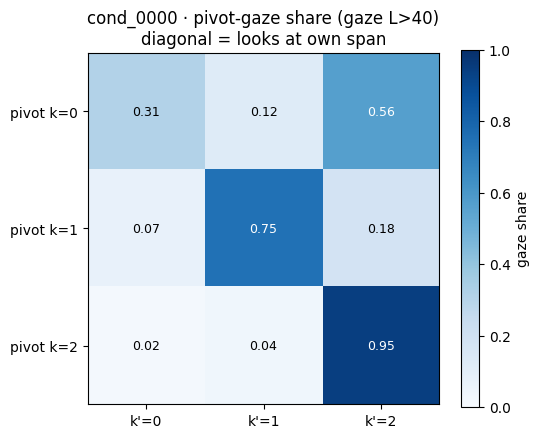

  k=0: n is less than or equal to 500
  k=1: n is positive
  k=2: n is a perfect square


In [19]:
# §A (cont.) — single-sample pivot-gaze matrix: rows = pivot of condition k, cols = candidate span k'.
# A diagonal-dominant matrix at δ=0 means the late gaze heads already 'know' which span to look at
# the moment the LM reaches the pivot.
MATRIX_SAMPLE = next(iter(samples))      # first scanned sample; set to any cond_XXXX
_Ls, _Hs = LH[list(LH)[0]]               # gaze L>40
attn = np.load(os.path.join(_attn_dir, MATRIX_SAMPLE, "attn.npz"), allow_pickle=True)["attn"]
seq = attn.shape[-1]
labels = json.load(open(os.path.join(_mono_dir, MATRIX_SAMPLE, "labels.json")))["labels"]
kr = json.load(open(os.path.join(_mono_dir, MATRIX_SAMPLE, "key_ranges.json")))["step_key_token_ranges"]
n = min(len(labels), len(kr))
kidx = {i: _key_idx(kr[i], seq) for i in range(n)}
keyed = [i for i in range(n) if kidx[i].size > 0 and labels[i].get("gen_token_range")]
if SKIP_LAST_MONO:
    keyed = [i for i in keyed if i != len(labels) - 1]
M = np.full((len(keyed), len(keyed)), np.nan)
for ri, k in enumerate(keyed):
    q0, _ = labels[k]["gen_token_range"]
    col = attn[_Ls, _Hs, q0, :].astype(np.float32)        # gaze from the pivot of k
    sc = np.array([col[:, kidx[i]].mean() for i in keyed])
    M[ri] = sc / sc.sum() if sc.sum() > 0 else sc
del attn
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(keyed))); ax.set_yticks(range(len(keyed)))
ax.set_xticklabels([f"k'={i}" for i in keyed]); ax.set_yticklabels([f"pivot k={i}" for i in keyed])
for ri in range(len(keyed)):
    for ci in range(len(keyed)):
        ax.text(ci, ri, f"{M[ri, ci]:.2f}", ha="center", va="center",
                color="white" if M[ri, ci] > 0.5 else "black", fontsize=9)
ax.set_title(f"{MATRIX_SAMPLE} · pivot-gaze share (gaze L>{LAYER_BOUNDARY})\ndiagonal = looks at own span")
fig.colorbar(im, ax=ax, shrink=0.8, label="gaze share")
plt.tight_layout(); plt.show()
for i in keyed:
    print(f"  k={i}: {labels[i]['step_text']}")

## §B · Single-pair per-head screen — which <L40 head sets the gaze target?

**Same-spec oid interchange.** Destination = the spec cut at the pivot for condition *i* (`b =`); source = the *same* spec cut at the pivot for condition *j* (`c =`). For each head in layers `< LAYER_BOUNDARY`, we transplant its **pivot o_proj-input** *j→i* and recompute the target signal

&nbsp;&nbsp;`T(span_k) = mean over [gaze heads, L>40] of mean over key-tokens s∈id_substrs(k) of attn[L,H, q=pivot, s]`

read at the destination's pivot query. **Headline = ΔT(span_target − span_orig)** relative to the unpatched baseline — a head scores high if moving *its* output alone redirects the late-layer gaze from condition *i* toward condition *j*.

*Mechanism:* o_proj-input patch via a `forward_pre_hook` (as in `forward_with_src_replacement`, last position only) + post-softmax gaze capture via `attention_interface_0.source.to_0.output` (as in nb06's knockout, verified for Qwen2.5), sliced to the pivot-query row so memory stays small. Heads are batched within each source layer ⇒ ~`LAYER_BOUNDARY`+2 forwards per pair. **Sanity:** patching *all* <L40 heads jointly should move ΔT a lot (the transferable ceiling).

In [45]:
import torch
from src.tokens import prepare_input
from src.functional import get_module_nnsight
from src.goals.head_loc_attn import get_o_proj_inputs_batch

### ---- single-pair config ----
ORIG_IDX   = 1   # condition the LM is ORIGINALLY about to implement (destination pivot, cut at `b =`)
TARGET_IDX = 2   # condition we try to REDIRECT TO (source pivot, cut at `c =`) — the installed intent
PIVOT_VARS = {0: "a", 1: "b", 2: "c", 3: "d"}
### ---------------------------
nH = mt.model.config.num_attention_heads
hd = mt.n_embd // nH
LAYERS_BELOW = list(range(0, LAYER_BOUNDARY))            # <L40 intervention set
GAZE_T = READOUT_SETS[f"gaze L>{LAYER_BOUNDARY}"]        # readout heads (from §A)
gaze_layers = sorted({l for l, _ in GAZE_T})
print(f"intervene over {len(LAYERS_BELOW)} layers x {nH} heads; readout = {len(GAZE_T)} gaze heads "
      f"across {len(gaze_layers)} layers (L>{LAYER_BOUNDARY})")

# ── pick a same-spec sample that has pivots for both conditions ───────────────
def _spans_for(sample):
    kr = json.load(open(os.path.join(CACHE_ROOT, MODULARITY, sample, "key_ranges.json")))["step_key_token_ranges"]
    labels = json.load(open(os.path.join(CACHE_ROOT, MODULARITY, sample, "labels.json")))["labels"]
    return kr, labels

PAIR_SAMPLE = None
for s in (samples if 'samples' in globals() else sorted(os.listdir(os.path.join(CACHE_ROOT, MODULARITY)))):
    try:
        kr, labels = _spans_for(s)
    except FileNotFoundError:
        continue
    if len(kr) > max(ORIG_IDX, TARGET_IDX) and all(len(kr[k]) and kr[k][0] for k in (ORIG_IDX, TARGET_IDX)):
        # both pivots must be findable in the cached generation
        try:
            build_prefill(s, PIVOT_VARS[ORIG_IDX], MODULARITY)
            build_prefill(s, PIVOT_VARS[TARGET_IDX], MODULARITY)
        except Exception:
            continue
        PAIR_SAMPLE = s; break
assert PAIR_SAMPLE is not None, "no same-spec sample with both pivots found"
kr, labels = _spans_for(PAIR_SAMPLE)
print(f"PAIR_SAMPLE = {PAIR_SAMPLE}")
for k in range(len(labels)):
    tag = "  <- ORIG (dest pivot)" if k == ORIG_IDX else ("  <- TARGET (source pivot)" if k == TARGET_IDX else "")
    print(f"  cond {k}: {labels[k]['step_text']}{tag}")

dest_prefill, _ = build_prefill(PAIR_SAMPLE, PIVOT_VARS[ORIG_IDX], MODULARITY)   # cut at `b =`
src_prefill,  _ = build_prefill(PAIR_SAMPLE, PIVOT_VARS[TARGET_IDX], MODULARITY)   # cut at `c =`

# ── span token indices (into the cached/prefill tokenization; spec is in the shared prefix) ──
def _key_idx_local(step_ranges, seq):
    idx = set()
    for r in step_ranges:
        if r:
            idx.update(t for t in range(int(r[0]), int(r[1])) if 0 <= t < seq)
    return np.array(sorted(idx), dtype=np.int64)

_dest_inp1 = prepare_input(prompts=[dest_prefill], tokenizer=mt)
assert int(_dest_inp1["attention_mask"].sum()) == _dest_inp1["input_ids"].shape[1], "unexpected padding (B=1)"
_seq = _dest_inp1["input_ids"].shape[1]
span_idx = [_key_idx_local(kr[k], _seq) for k in range(len(kr))]
# decode sanity: do the span tokens match the spec id_substrs?
for k in (ORIG_IDX, TARGET_IDX):
    toks = mt.tokenizer.decode(_dest_inp1["input_ids"][0, span_idx[k]].tolist())
    print(f"  span[{k}] tokens -> {toks!r}")

# ── source / dest o_proj inputs at the pivot (last token) for <L40 layers ─────
src_oproj  = get_o_proj_inputs_batch(mt, [src_prefill],  LAYERS_BELOW)   # {l: (1, n_embd)}
dest_oproj = get_o_proj_inputs_batch(mt, [dest_prefill], LAYERS_BELOW)
oproj_diff = {l: (src_oproj[l][0] - dest_oproj[l][0]) for l in LAYERS_BELOW}  # (n_embd,) src-dest per layer
print("cached source/dest pivot o_proj inputs for", len(LAYERS_BELOW), "layers")

# ── gaze score = raw Q·K affinity (02-style), computed ourselves ─────────────
# Lock the gaze heads, pre-extract their q_proj/k_proj. During a (patched) forward we only grab
# the residual latent feeding those projections; we project + dot ourselves (no .output/softmax).
# Keys are constant under a pivot-only patch (causality), so the whole causal effect is on the query.
### ---- gaze-affinity config ----
NORMALIZE    = False   # True -> cosine similarity ; False -> raw dot product (no /sqrt(d))
INCLUDE_ROPE = True   # apply rotary to q,k before the dot
GAZE_DEVICE  = "cuda:0"
### -------------------------------
_CFG      = mt.model.config
N_Q       = _CFG.num_attention_heads
N_KV      = getattr(_CFG, "num_key_value_heads", N_Q)
HEAD_DIM  = getattr(_CFG, "head_dim", mt.n_embd // N_Q)
GQA_GROUP = N_Q // N_KV
print(f"N_Q={N_Q} N_KV={N_KV} HEAD_DIM={HEAD_DIM} GQA_GROUP={GQA_GROUP} | NORMALIZE={NORMALIZE} ROPE={INCLUDE_ROPE}")

# frozen q_proj/k_proj weights+biases for the gaze layers (extracted once)
gaze_W = {}
for L in gaze_layers:
    _b = mt.attn_module_name_format.format(L)
    qp = get_module_nnsight(mt._model, _b + ".q_proj")
    kp = get_module_nnsight(mt._model, _b + ".k_proj")
    gaze_W[L] = (qp.weight.detach(), None if qp.bias is None else qp.bias.detach(),
                 kp.weight.detach(), None if kp.bias is None else kp.bias.detach())
heads_by_layer = {}
for (L, h) in GAZE_T:
    heads_by_layer.setdefault(L, []).append(h)


def _proj(x, W, b, n_heads):
    """x (..., n_embd) -> (..., n_heads, HEAD_DIM) via a frozen projection."""
    y = torch.matmul(x, W.t().to(x.dtype))
    if b is not None:
        y = y + b.to(x.dtype)
    return y.view(*x.shape[:-1], n_heads, HEAD_DIM)


def _maybe_rope(vec, pos, n_heads):
    """vec (B, P, n_heads, D); rotate at integer positions `pos` (LongTensor (P,)). Manual RoPE so it
    stays on `vec`'s device — the model is split across GPUs, and the rotary module's buffers may live
    on a different device than the gaze-layer latents."""
    if not INCLUDE_ROPE:
        return vec
    dev, dt = vec.device, vec.dtype
    rotary = mt._model.model.rotary_emb
    inv_freq = rotary.inv_freq.to(dev).float()                       # (D/2,)
    scaling = float(getattr(rotary, "attention_scaling", 1.0))
    freqs = torch.outer(pos.to(dev).float(), inv_freq)              # (P, D/2)
    emb = torch.cat([freqs, freqs], dim=-1)                          # (P, D)
    cos = (emb.cos() * scaling).to(dt)[None, :, None, :]            # (1, P, 1, D) -> broadcast B, n_heads
    sin = (emb.sin() * scaling).to(dt)[None, :, None, :]
    d = vec.shape[-1]
    rot = torch.cat([-vec[..., d // 2:], vec[..., : d // 2]], dim=-1)   # rotate_half (HF convention)
    return vec * cos + rot * sin


def _gaze_latents(dest_inputs, pre_hooks=()):
    """Run forward with pre_hooks (o_proj patches); capture each gaze layer's q_proj INPUT latent
    (== k_proj input). Returns {L: (B, seq, n_embd)}, grad-connected — no .output dependence."""
    handles, saved = [], {}
    try:
        for mod, fn in pre_hooks:
            handles.append(mod.register_forward_pre_hook(fn))
        for L in gaze_layers:
            qp = get_module_nnsight(mt._model, mt.attn_module_name_format.format(L) + ".q_proj")
            def mk(L_):
                def cap(module, args):
                    saved[L_] = args[0]
                    return None
                return cap
            handles.append(qp.register_forward_pre_hook(mk(L)))
        mt._model(**dict(dest_inputs), use_cache=False)
    finally:
        for h in handles:
            h.remove()
    return saved


def compute_gaze_T(dest_inputs, spans, pre_hooks=()):
    """T (B, n_cond): mean over GAZE_T heads of the pivot query's raw Q·K affinity to each span's
    key tokens. `spans` = list of token-index arrays. Differentiable through any mask in pre_hooks."""
    lat = _gaze_latents(dest_inputs, pre_hooks)
    B   = lat[gaze_layers[0]].shape[0]
    seq = lat[gaze_layers[0]].shape[1]
    pos = torch.arange(seq)
    T = torch.zeros(B, len(spans), device=GAZE_DEVICE)
    n_used = 0
    for L, hs in heads_by_layer.items():
        x = lat[L]                                                           # (B, seq, n_embd)
        Wq, bq, Wk, bk = gaze_W[L]
        Q = _maybe_rope(_proj(x[:, -1:, :], Wq, bq, N_Q), pos[-1:], N_Q)[:, 0]   # (B, N_Q, D) pivot query
        K = _maybe_rope(_proj(x, Wk, bk, N_KV), pos, N_KV)                       # (B, seq, N_KV, D) keys
        for h in hs:
            qh = Q[:, h, :]                                                  # (B, D)
            kh = K[:, :, h // GQA_GROUP, :]                                  # (B, seq, D)  (GQA)
            if NORMALIZE:
                qh = qh / (qh.norm(dim=-1, keepdim=True) + 1e-9)
                kh = kh / (kh.norm(dim=-1, keepdim=True) + 1e-9)
            for c, span in enumerate(spans):
                idx = torch.as_tensor(span, dtype=torch.long, device=kh.device)
                if idx.numel() == 0:
                    continue
                aff = (qh.unsqueeze(1) * kh[:, idx, :]).sum(-1).mean(dim=1)  # (B,) over span keys
                T[:, c] = T[:, c] + aff.to(GAZE_DEVICE)
            n_used += 1
    return T / max(n_used, 1)


def add_patch_hooks(layer, add):
    """Additive o_proj-input patch at the pivot (last pos). add: (B, n_embd)."""
    o_proj = get_module_nnsight(mt._model, mt.attn_module_name_format.format(layer) + ".o_proj")
    def pre(module, args):
        x = args[0].clone()
        x[:, -1, :] = x[:, -1, :] + add.to(x.device, x.dtype)
        return (x,) + tuple(args[1:])
    return [(o_proj, pre)]


def mask_patch_hooks(layers, src_hv, mask):
    """Mask-weighted per-head o_proj-input transplant at the pivot. src_hv: (len(layers), n_embd)."""
    hooks, src_b = [], src_hv.unsqueeze(0)
    for li, layer in enumerate(layers):
        o_proj = get_module_nnsight(mt._model, mt.attn_module_name_format.format(layer) + ".o_proj")
        def mk(li_):
            def pre(module, args):
                x = args[0]; dev, dt, B_ = x.device, x.dtype, x.shape[0]
                src3 = src_b[:, li_].to(dev).view(B_, N_Q, HEAD_DIM)
                m = mask.values[li_].to(dev).view(1, N_Q, 1)
                cas3 = x[:, -1, :].float().view(B_, N_Q, HEAD_DIM)
                new_last = (m * src3 + (1 - m) * cas3).view(B_, mt.n_embd).to(dt)
                return (torch.cat([x[:, :-1, :], new_last.unsqueeze(1)], dim=1),) + tuple(args[1:])
            return pre
        hooks.append((o_proj, mk(li)))
    return hooks

print("setup ready: compute_gaze_T(), add_patch_hooks(), mask_patch_hooks()")


intervene over 40 layers x 40 heads; readout = 254 gaze heads across 22 layers (L>40)
PAIR_SAMPLE = cond_0000
  cond 0: n is less than or equal to 500
  cond 1: n is positive  <- ORIG (dest pivot)
  cond 2: n is a perfect square  <- TARGET (source pivot)
  cond 3: n is between 10 and 200 (inclusive)
  span[1] tokens -> ' positive'
  span[2] tokens -> ' perfect square'
cached source/dest pivot o_proj inputs for 40 layers
N_Q=40 N_KV=8 HEAD_DIM=128 GQA_GROUP=5 | NORMALIZE=False ROPE=True
setup ready: compute_gaze_T(), add_patch_hooks(), mask_patch_hooks()


### §B.0 · Baseline gaze at the ` =` pivot — *no intervention* (read-out sanity)

Before any sweep/optimization, print the bare gaze numbers at the ` =` token. **Key check:** the cached `attn.npz` is **value-weighted** (`softmax·‖V‖`, the criterion `GAZE_T` was selected on), while `capture_gaze_attn` reads **raw post-softmax** probs. We print both per condition span so we can see (a) whether the gaze concentrates on the ORIG span at all, and (b) whether raw vs value-weighted disagree — if cached-VW is diagonal but live-raw is flat, the read-out (and hence the optimization target) is mis-specified and should be value-weighted.

In [46]:
# baseline gaze @ ` =` : raw Q·K gaze score per instruction span (compute_gaze_T, no intervention)
M_DIAG = 5
_cand = (samples if 'samples' in globals() else sorted(os.listdir(os.path.join(CACHE_ROOT, MODULARITY))))
diag_samples = []
for s in _cand:
    try:
        kr, labels = _spans_for(s)
    except FileNotFoundError:
        continue
    if len(kr) > ORIG_IDX and kr[ORIG_IDX] and kr[ORIG_IDX][0]:
        diag_samples.append(s)
    if len(diag_samples) >= M_DIAG:
        break

for s in diag_samples:
    kr, labels = _spans_for(s)
    prefill, _ = build_prefill(s, PIVOT_VARS[ORIG_IDX], MODULARITY)
    di = prepare_input(prompts=[prefill], tokenizer=mt)
    pivot_abs = di['input_ids'].shape[1] - 1            # ` =` index (last token, no pad at B=1)
    nC = len(kr)
    spans = [_key_idx_local(kr[k], pivot_abs + 1) for k in range(nC)]
    with torch.no_grad():
        T = compute_gaze_T(di, spans)[0].cpu().numpy()
    print(f"=== sample {s}  (pivot ` =` @ idx {pivot_abs}) ===")
    for k in range(nC):
        mark = "   <- implementing (b)" if k == ORIG_IDX else ""
        print(f"  instr{k}: gaze={T[k]:+.4f}   {labels[k]['step_text'][:46]}{mark}")
    print()


=== sample cond_0000  (pivot ` =` @ idx 253) ===
  instr0: gaze=+66.7462   n is less than or equal to 500
  instr1: gaze=+102.0494   n is positive   <- implementing (b)
  instr2: gaze=+56.5635   n is a perfect square
  instr3: gaze=+53.2146   n is between 10 and 200 (inclusive)

=== sample cond_0001  (pivot ` =` @ idx 241) ===
  instr0: gaze=+56.1971   n is between 0 and 100 (inclusive)
  instr1: gaze=+93.9664   n is odd   <- implementing (b)
  instr2: gaze=+64.0351   n is a perfect square

=== sample cond_0002  (pivot ` =` @ idx 251) ===
  instr0: gaze=+63.7529   n is odd
  instr1: gaze=+78.5422   n is a perfect square   <- implementing (b)
  instr2: gaze=+37.0632   n is even
  instr3: gaze=+37.0632   n is even
  instr4: gaze=+45.5896   the sum of n's digits is greater than 15

=== sample cond_0003  (pivot ` =` @ idx 280) ===
  instr0: gaze=+50.9058   the sum of n's digits is greater than 15
  instr1: gaze=+90.2045   n is a prime number   <- implementing (b)
  instr2: gaze=+51.0440   

baseline gaze @ dest pivot (`b =`):  cond0=+0.2235  cond1=+0.3251  cond2=+0.1772  cond3=+0.1694
baseline headline T(TARGET=2) - T(ORIG=1) = -0.1479


per-head screen:   0%|          | 0/40 [00:00<?, ?it/s]


SANITY  all <L40 heads jointly:  ΔT = +0.0399   (single-head max = +0.0040)


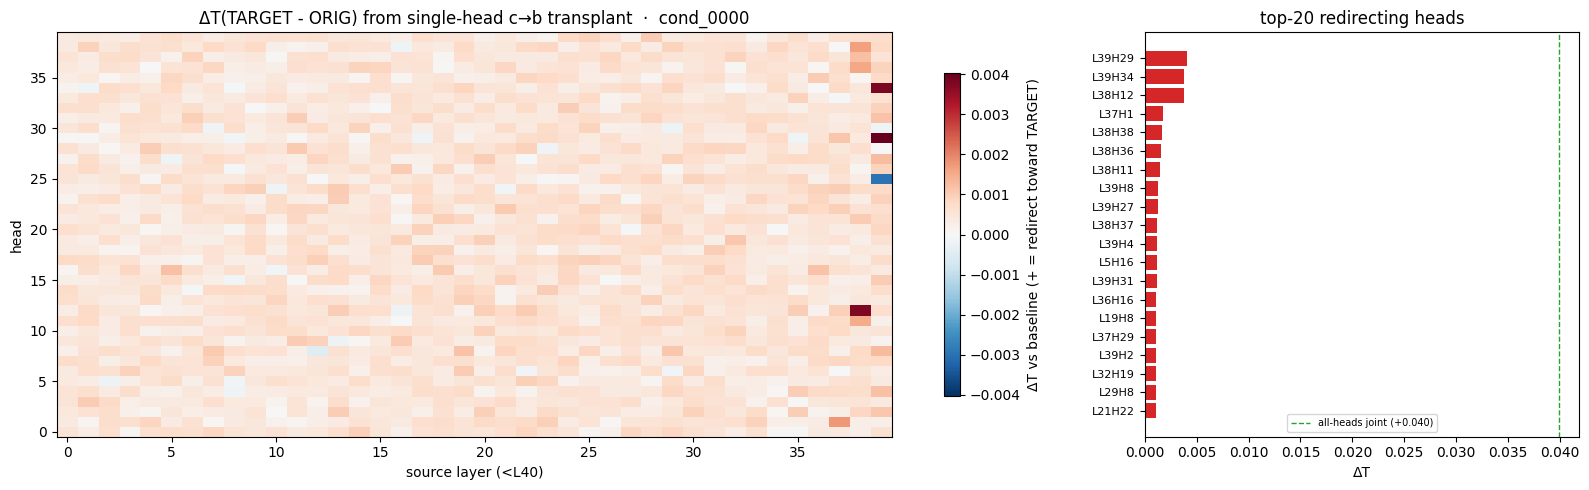


top-10 <L40 decision-head candidates (single-head c→b redirect):
  L39 H29   ΔT=+0.0040
  L39 H34   ΔT=+0.0038
  L38 H12   ΔT=+0.0038
  L37 H 1   ΔT=+0.0018
  L38 H38   ΔT=+0.0016
  L38 H36   ΔT=+0.0015
  L38 H11   ΔT=+0.0015
  L39 H 8   ΔT=+0.0013
  L39 H27   ΔT=+0.0012
  L38 H37   ΔT=+0.0012


In [36]:
# ── baseline (no patch) ──────────────────────────────────────────────────────
with torch.no_grad():
    T_base = compute_gaze_T(_dest_inp1, span_idx)[0].cpu().numpy()            # (n_cond,)
base_headline = T_base[TARGET_IDX] - T_base[ORIG_IDX]
print(f"baseline gaze @ dest pivot (`{PIVOT_VARS[ORIG_IDX]} =`):  "
      + "  ".join(f"cond{k}={T_base[k]:+.4f}" for k in range(len(T_base))))
print(f"baseline headline T(TARGET={TARGET_IDX}) - T(ORIG={ORIG_IDX}) = {base_headline:+.4f}")

# ── per-head screen: batch heads within each source layer ────────────────────
dest_inp_B = prepare_input(prompts=[dest_prefill] * nH, tokenizer=mt)
deltaT = np.full((LAYER_BOUNDARY, nH), np.nan)
for l in tqdm(LAYERS_BELOW, desc="per-head screen"):
    diff = oproj_diff[l]                                     # (n_embd,) src-dest
    add = torch.zeros(nH, mt.n_embd, dtype=torch.float32)    # element b patches head b only
    for b in range(nH):
        add[b, b * hd:(b + 1) * hd] = diff[b * hd:(b + 1) * hd]
    with torch.no_grad():
        T = compute_gaze_T(dest_inp_B, span_idx, pre_hooks=add_patch_hooks(l, add)).cpu().numpy()  # (nH, n_cond)
    deltaT[l] = (T[:, TARGET_IDX] - T[:, ORIG_IDX]) - base_headline

# ── sanity: all <L40 heads jointly (transferable ceiling) ────────────────────
joint_hooks = []
for l in LAYERS_BELOW:
    joint_hooks += add_patch_hooks(l, oproj_diff[l].unsqueeze(0))    # (1, n_embd) per layer
with torch.no_grad():
    T_joint = compute_gaze_T(_dest_inp1, span_idx, pre_hooks=joint_hooks)[0].cpu().numpy()
joint_headline = (T_joint[TARGET_IDX] - T_joint[ORIG_IDX]) - base_headline
print(f"\nSANITY  all <L{LAYER_BOUNDARY} heads jointly:  ΔT = {joint_headline:+.4f}   "
      f"(single-head max = {np.nanmax(deltaT):+.4f})")

# ── plots: ΔT heatmap (layer x head) + top-k heads ───────────────────────────
import matplotlib.pyplot as plt
fig, (axh, axb) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.4, 1]})
vlim = np.nanmax(np.abs(deltaT))
im = axh.imshow(deltaT.T, aspect="auto", cmap="RdBu_r", vmin=-vlim, vmax=vlim, origin="lower")
axh.set_xlabel("source layer (<L%d)" % LAYER_BOUNDARY); axh.set_ylabel("head")
axh.set_title(f"ΔT(TARGET - ORIG) from single-head c→b transplant  ·  {PAIR_SAMPLE}")
fig.colorbar(im, ax=axh, shrink=0.8, label="ΔT vs baseline (+ = redirect toward TARGET)")

flat = [((l, h), deltaT[l, h]) for l in LAYERS_BELOW for h in range(nH) if not np.isnan(deltaT[l, h])]
topk = sorted(flat, key=lambda x: x[1], reverse=True)[:20]
labels_k = [f"L{l}H{h}" for (l, h), _ in topk]
axb.barh(range(len(topk)), [v for _, v in topk], color="tab:red")
axb.set_yticks(range(len(topk))); axb.set_yticklabels(labels_k, fontsize=8)
axb.invert_yaxis(); axb.axvline(0, color="k", lw=0.6)
axb.axvline(joint_headline, color="tab:green", ls="--", lw=1, label=f"all-heads joint ({joint_headline:+.3f})")
axb.set_xlabel("ΔT"); axb.set_title("top-20 redirecting heads"); axb.legend(fontsize=7)
plt.tight_layout(); plt.show()

print("\ntop-10 <L40 decision-head candidates (single-head c→b redirect):")
for (l, h), v in topk[:10]:
    print(f"  L{l:2d} H{h:2d}   ΔT={v:+.4f}")


## §D · Jointly train a binary head-mask over the <L40 heads (gaze objective)

Approach 2. Reuse the goalscope machinery — `HeadMask` (box-constrained `[0,1]`, projected GD, `λ·mean(mask)` sparsity, `selected_heads`) — but swap **objective** and **forward**:

- **forward** (`forward_gaze_masked`): the same grad-safe per-head o_proj-input interpolation as `forward_with_src_replacement` (`mask·src + (1−mask)·dest_cascade` at the **pivot** position), but returns the **>L40 gaze attention** (`output_attentions=True`, eager) at the pivot query — differentiable w.r.t. `mask.values`.
- **loss**: `L = −(T(span_target) − T(span_orig)) + λ·mean(mask)` — install the *source* condition's gaze while suppressing the destination's, with the fewest <L40 heads.

Mask starts all-ones (every <L40 head transplanted = the joint ceiling); sparsity prunes to the causal minimum. We train over many same-spec oid pairs (one pair = one optimizer micro-step via gradient accumulation, so B=1 ⇒ no padding/offset and low attention memory). Output: the trained mask, `selected_heads(threshold)`, and overlap (Jaccard) with the §B single-head screen.

In [47]:
from torch.optim import AdamW
from src.goals.head_loc_attn import HeadMask

### ---- gaze-mask data config ----
N_PAIRS_MASK = 40        # same-spec oid pairs (ORIG_IDX dest pivot, TARGET_IDX source pivot)
MASK_DEVICE  = "cuda:0"  # mask params + loss reduction live here
### -------------------------------

def build_gaze_pair(sample):
    """One same-spec oid pair -> dict(dest_inputs B=1, src_hv (Lbelow,n_embd), span_orig, span_target).
    Returns None if the sample lacks both pivots or unexpectedly left-pads."""
    try:
        kr, labels = _spans_for(sample)
    except FileNotFoundError:
        return None
    if len(kr) <= max(ORIG_IDX, TARGET_IDX):
        return None
    if not (kr[ORIG_IDX] and kr[ORIG_IDX][0] and kr[TARGET_IDX] and kr[TARGET_IDX][0]):
        return None
    try:
        dst, _ = build_prefill(sample, PIVOT_VARS[ORIG_IDX], MODULARITY)
        src, _ = build_prefill(sample, PIVOT_VARS[TARGET_IDX], MODULARITY)
    except Exception:
        return None
    di = prepare_input(prompts=[dst], tokenizer=mt)
    seq = di["input_ids"].shape[1]
    if int(di["attention_mask"].sum()) != seq:   # B=1 should never pad
        return None
    s_orig, s_target = _key_idx_local(kr[ORIG_IDX], seq), _key_idx_local(kr[TARGET_IDX], seq)
    if s_orig.size == 0 or s_target.size == 0:
        return None
    shv = get_o_proj_inputs_batch(mt, [src], LAYERS_BELOW)         # {l: (1, n_embd)}
    src_hv = torch.stack([shv[l][0] for l in LAYERS_BELOW])        # (Lbelow, n_embd) float32 CPU
    return dict(sample=sample, dest_inputs=di, src_hv=src_hv,
                span_orig=torch.tensor(s_orig), span_target=torch.tensor(s_target))

_pool = (samples if 'samples' in globals() else
         sorted(os.listdir(os.path.join(CACHE_ROOT, MODULARITY))))
gaze_pairs = []
for s in tqdm(_pool, desc="build pairs"):
    p = build_gaze_pair(s)
    if p is not None:
        gaze_pairs.append(p)
    if len(gaze_pairs) >= N_PAIRS_MASK:
        break
print(f"built {len(gaze_pairs)} same-spec oid pairs (i={ORIG_IDX}, j={TARGET_IDX})")
assert len(gaze_pairs) >= 4, "need a few pairs to train"


build pairs:   0%|          | 0/50 [00:00<?, ?it/s]

built 40 same-spec oid pairs (i=1, j=2)


### §D.0 · token-location sanity — pivots & instruction-span keys

Tokenize the destination (cut at `ORIG`) and source (cut at `TARGET`) prefills, locate the **destination pivot** (last token, the ` =`), the **source pivot**, and the **key tokens** of the ORIG/TARGET instruction spans, and highlight them in-place. The keys should land on the spec keywords in the instruction; the pivots on the ` =` we patch/read.

In [52]:
from rich.markup import escape

STY_PIVOT  = "bold black on salmon1"
STY_ORIG   = "black on green"
STY_TARGET = "black on magenta"

VIS_SAMPLE = gaze_pairs[0]["sample"] if ('gaze_pairs' in globals() and gaze_pairs) else _pool[0]
kr, labels = _spans_for(VIS_SAMPLE)
dst, _ = build_prefill(VIS_SAMPLE, PIVOT_VARS[ORIG_IDX], MODULARITY)    # dest: cut at ORIG `=`
src, _ = build_prefill(VIS_SAMPLE, PIVOT_VARS[TARGET_IDX], MODULARITY)  # src:  cut at TARGET `=`
dest_ids = prepare_input(prompts=[dst], tokenizer=mt)["input_ids"][0].tolist()
src_ids  = prepare_input(prompts=[src], tokenizer=mt)["input_ids"][0].tolist()
dest_pivot, src_pivot = len(dest_ids) - 1, len(src_ids) - 1
span_orig   = sorted(_key_idx_local(kr[ORIG_IDX],   len(dest_ids)).tolist())
span_target = sorted(_key_idx_local(kr[TARGET_IDX], len(dest_ids)).tolist())

def _render(ids, marks):
    out = []
    for i, tid in enumerate(ids):
        piece = escape(mt.tokenizer.decode([tid]))
        sty = marks.get(i)
        out.append(f"[{sty}]{piece}[/{sty}]" if sty else piece)
    return "".join(out)

dest_marks = {dest_pivot: STY_PIVOT}
dest_marks.update({i: STY_ORIG for i in span_orig})
dest_marks.update({i: STY_TARGET for i in span_target})

rich_print(f"[bold]sample {VIS_SAMPLE}[/bold]   ORIG=cond{ORIG_IDX} (`{PIVOT_VARS[ORIG_IDX]} =`)   "
           f"TARGET=cond{TARGET_IDX} (`{PIVOT_VARS[TARGET_IDX]} =`)")
rich_print(f"legend:  [{STY_PIVOT}] pivot ` =` [/{STY_PIVOT}]   "
           f"[{STY_ORIG}] ORIG span keys [/{STY_ORIG}]   [{STY_TARGET}] TARGET span keys [/{STY_TARGET}]")
rich_print(
    f"\n[bold]DEST pivot[/bold] idx {dest_pivot} = {mt.tokenizer.decode([dest_ids[dest_pivot]])!r}   |   "
    f"ORIG keys {span_orig} -> {mt.tokenizer.decode([dest_ids[i] for i in span_orig])!r}   |   "
    f"TARGET keys {span_target} -> {mt.tokenizer.decode([dest_ids[i] for i in span_target])!r}"
)
rich_print(f"[bold]SRC pivot[/bold] idx {src_pivot} = {mt.tokenizer.decode([src_ids[src_pivot]])!r}")

rich_print("\n[bold]── DESTINATION prompt ──[/bold]")
rich_print(_render(dest_ids, dest_marks))
rich_print("\n[bold]── SOURCE prompt (only pivot marked) ──[/bold]")
rich_print(_render(src_ids, {src_pivot: STY_PIVOT}))

sample cond_0000   ORIG=cond1 (`b =`)   TARGET=cond2 (`c =`)

legend:   pivot ` =`     ORIG span keys     TARGET span keys 

DEST pivot idx 253 = ' ='   |   ORIG keys [86] -> ' positive'   |   TARGET keys [93, 94] -> ' perfect square'

SRC pivot idx 261 = ' ='

── DESTINATION prompt ──

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is less than or equal to 500
2. n is positive
3. n is a perfect square
4. n is between 10 and 200 (inclusive)

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n <= 500
    b =

── SOURCE prompt (only pivot marked) ──

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is less than or equal to 500
2. n is positive
3. n is a perfect square
4. n is between 10 and 200 (inclusive)

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n <= 500
    b = n > 0
    c =

epoch 0:   0%|          | 0/32 [00:00<?, ?it/s]

epoch  0  train ΔT=-16.8668  val ΔT=-21.5375  mean(mask)=0.941  n_active(>0.5)=1600


epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

epoch  1  train ΔT=-16.4424  val ΔT=-20.9606  mean(mask)=0.892  n_active(>0.5)=1600


epoch 2:   0%|          | 0/32 [00:00<?, ?it/s]

epoch  2  train ΔT=-15.9151  val ΔT=-20.2949  mean(mask)=0.840  n_active(>0.5)=1361


... (14 outputs left out)

epoch 10:   0%|          | 0/32 [00:00<?, ?it/s]

epoch 10  train ΔT=-12.9987  val ΔT=-17.0825  mean(mask)=0.657  n_active(>0.5)=1063


epoch 11:   0%|          | 0/32 [00:00<?, ?it/s]

epoch 11  train ΔT=-12.9398  val ΔT=-17.1901  mean(mask)=0.651  n_active(>0.5)=1047

selected 1047 <L40 decision heads (mask>0.5)


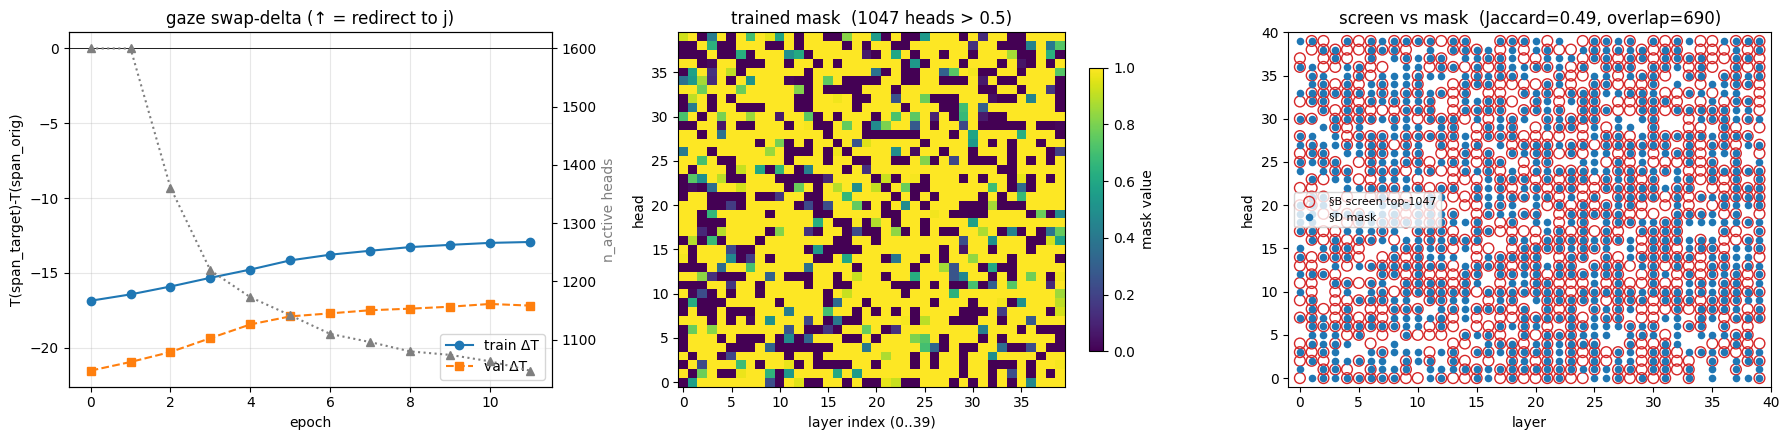

top decision heads: [(0, 1), (0, 3), (0, 7), (0, 10), (0, 12), (0, 15), (0, 17), (0, 18), (0, 19), (0, 20), (0, 24), (0, 25), (0, 27), (0, 28), (0, 33)]


In [48]:
MASK_DEVICE = GAZE_DEVICE      # mask params + loss reduction live where compute_gaze_T reduces

def swap_delta(pair, mask):
    """T(TARGET) - T(ORIG) at the pivot, under the mask-weighted <L40 transplant. Differentiable."""
    T = compute_gaze_T(pair["dest_inputs"], [pair["span_orig"], pair["span_target"]],
                       pre_hooks=mask_patch_hooks(LAYERS_BELOW, pair["src_hv"], mask))[0]
    return T[1] - T[0]

### ---- training config ----
N_EPOCHS_MASK  = 12
LR_MASK        = 5e-2
LAMBDA_SPARSE  = 2e-2
ACCUM          = 8        # pairs per optimizer step (grad accumulation; B=1 each)
SEL_THRESHOLD  = 0.5
### --------------------------
import random as _rnd
_rng = _rnd.Random(0)
n_val = max(1, int(0.2 * len(gaze_pairs)))
val_pairs, train_pairs = gaze_pairs[:n_val], gaze_pairs[n_val:]

for p in mt._model.parameters():
    p.requires_grad_(False)
mask = HeadMask(len(LAYERS_BELOW), nH).to(MASK_DEVICE)
opt = AdamW(mask.parameters(), lr=LR_MASK)
hist = {"causal": [], "sparse": [], "n_active": [], "val_delta": []}

for epoch in range(N_EPOCHS_MASK):
    order = train_pairs[:]; _rng.shuffle(order)
    opt.zero_grad(); ep_causal = 0.0
    for i, pair in enumerate(tqdm(order, desc=f"epoch {epoch}", leave=False)):
        d = swap_delta(pair, mask)
        loss_causal = -d
        loss = (loss_causal + LAMBDA_SPARSE * mask.values.mean()) / ACCUM
        loss.backward()
        ep_causal += float(d.detach())
        if (i + 1) % ACCUM == 0 or (i + 1) == len(order):
            opt.step(); mask.clamp_(); opt.zero_grad()
    with torch.no_grad():
        vds = [float(swap_delta(p, mask).detach()) for p in val_pairs]
    hist["causal"].append(ep_causal / len(order))
    hist["sparse"].append(float(mask.values.mean()))
    hist["n_active"].append(mask.n_active(SEL_THRESHOLD))
    hist["val_delta"].append(float(np.mean(vds)))
    print(f"epoch {epoch:2d}  train ΔT={hist['causal'][-1]:+.4f}  val ΔT={hist['val_delta'][-1]:+.4f}  "
          f"mean(mask)={hist['sparse'][-1]:.3f}  n_active(>{SEL_THRESHOLD})={hist['n_active'][-1]}")

decision_heads = mask.selected_heads(LAYERS_BELOW, threshold=SEL_THRESHOLD)
print(f"\nselected {len(decision_heads)} <L{LAYER_BOUNDARY} decision heads (mask>{SEL_THRESHOLD})")

# ---- plots: training curves + mask heatmap + overlap with §B screen ----
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ep = range(N_EPOCHS_MASK)
axes[0].plot(ep, hist["causal"], "o-", label="train ΔT")
axes[0].plot(ep, hist["val_delta"], "s--", label="val ΔT")
axes[0].axhline(0, color="k", lw=0.6); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("T(span_target)-T(span_orig)")
axes[0].set_title("gaze swap-delta (↑ = redirect to j)"); axes[0].legend(); axes[0].grid(alpha=0.3)
ax2 = axes[0].twinx(); ax2.plot(ep, hist["n_active"], "^:", color="tab:gray", label="n_active")
ax2.set_ylabel("n_active heads", color="tab:gray")
mv = mask.values.detach().cpu().numpy()
im = axes[1].imshow(mv.T, aspect="auto", cmap="viridis", vmin=0, vmax=1, origin="lower")
axes[1].set_xlabel(f"layer index (0..{LAYER_BOUNDARY-1})"); axes[1].set_ylabel("head")
axes[1].set_title(f"trained mask  ({len(decision_heads)} heads > {SEL_THRESHOLD})")
fig.colorbar(im, ax=axes[1], shrink=0.8, label="mask value")
if 'deltaT' in globals():
    screen_top = {lh for lh, _ in sorted(
        [((l, h), deltaT[l, h]) for l in LAYERS_BELOW for h in range(nH) if not np.isnan(deltaT[l, h])],
        key=lambda x: x[1], reverse=True)[:len(decision_heads)]}
    dset = set(decision_heads); inter = dset & screen_top
    jac = len(inter) / len(dset | screen_top) if (dset | screen_top) else 0.0
    axes[2].scatter([l for l, _ in screen_top], [h for _, h in screen_top], s=60, facecolors='none',
                    edgecolors='tab:red', label=f'§B screen top-{len(decision_heads)}')
    axes[2].scatter([l for l, _ in dset], [h for _, h in dset], s=20, c='tab:blue', label='§D mask')
    axes[2].set_xlim(-1, LAYER_BOUNDARY); axes[2].set_ylim(-1, nH)
    axes[2].set_xlabel('layer'); axes[2].set_ylabel('head')
    axes[2].set_title(f'screen vs mask  (Jaccard={jac:.2f}, overlap={len(inter)})'); axes[2].legend(fontsize=8)
else:
    axes[2].text(0.5, 0.5, 'run §B screen for overlap', ha='center', va='center'); axes[2].axis('off')
plt.tight_layout(); plt.show()

print("top decision heads:", sorted(decision_heads, key=lambda lh: mv[LAYERS_BELOW.index(lh[0]), lh[1]],
                                     reverse=True)[:15])

## §E · Load & inspect script results

Utilities to load the artifacts written by `scripts/clock/screen_oid_gaze.py` (`screen.npz` + `meta.json`) and `scripts/clock/train_oid_gaze_mask.py` (`mask.pt` + `meta.json`) under `results/.../oid_gaze/{screen,mask}/<tag>/`. **File-only — no model forward**, so run these any time after a script finishes (needs only `CACHE_ROOT`).

In [ ]:
import os, json
import numpy as np
import torch
import matplotlib.pyplot as plt

OID_GAZE_ROOT = os.path.join(CACHE_ROOT, "oid_gaze")

def list_results(kind):
    """kind in {'screen','mask'} -> [(tag, dir, mtime)] newest first."""
    d = os.path.join(OID_GAZE_ROOT, kind)
    if not os.path.isdir(d):
        return []
    items = [(t, os.path.join(d, t), os.path.getmtime(os.path.join(d, t)))
             for t in os.listdir(d) if os.path.isdir(os.path.join(d, t))]
    return sorted(items, key=lambda x: x[2], reverse=True)

def _pick(kind, tag=None):
    items = list_results(kind)
    assert items, f"no {kind} results under {os.path.join(OID_GAZE_ROOT, kind)}"
    if tag is None:
        return items[0][1]                       # newest by mtime
    match = [it for it in items if tag in it[0]]
    assert match, f"no {kind} result matching {tag!r}; have: {[it[0] for it in items]}"
    return match[0][1]

def load_screen(tag=None):
    d = _pick("screen", tag)
    npz = np.load(os.path.join(d, "screen.npz"), allow_pickle=True)
    out = {k: npz[k] for k in npz.files}
    out["meta"] = json.load(open(os.path.join(d, "meta.json")))
    out["dir"] = d
    return out

def load_mask(tag=None):
    d = _pick("mask", tag)
    ckpt = torch.load(os.path.join(d, "mask.pt"), map_location="cpu")
    ckpt["meta"] = json.load(open(os.path.join(d, "meta.json")))
    ckpt["dir"] = d
    return ckpt

print("loaders ready: list_results(kind), load_screen(tag=None), load_mask(tag=None)")
for _kind in ("screen", "mask"):
    _r = list_results(_kind)
    print(f"{_kind}: {len(_r)} result(s)" + ("" if _r else "  (none yet)"))
    for t, _, _ in _r:
        print(f"   - {t}")

In [ ]:
# ── inspect a SCREEN result ──
SCREEN_TAG = None     # None = newest; else a substring of the tag dir
S = load_screen(SCREEN_TAG)
deltaT, base_hl, joint_hl = S["deltaT"], S["base_hl"], S["joint_hl"]
layers_below = [int(x) for x in S["layers_below"]]
mean_dT, std_dT = np.nanmean(deltaT, axis=0), np.nanstd(deltaT, axis=0)
nH = mean_dT.shape[1]
m = S["meta"]
print(f"[{os.path.basename(S['dir'])}]  {deltaT.shape[0]} pairs · {m['n_gaze_heads']} gaze heads · "
      f"orig={m['orig_idx']} target={m['target_idx']} · {'cos' if m['normalize'] else 'dot'}"
      f"{' +rope' if m['include_rope'] else ''}")
print(f"baseline swap-delta T(target)-T(orig): {base_hl.mean():+.4f} ± {base_hl.std():.4f}")
print(f"joint (all <L{m['layer_boundary']}) swap-delta:   {joint_hl.mean():+.4f} ± {joint_hl.std():.4f}")
flat = [((l, h), float(mean_dT[l, h])) for l in layers_below for h in range(nH) if not np.isnan(mean_dT[l, h])]
top = sorted(flat, key=lambda x: x[1], reverse=True)[:20]
print("top-15 redirecting heads (mean ΔT over pairs):")
for (l, h), v in top[:15]:
    print(f"  L{l:2d} H{h:2d}  ΔT={v:+.4f} ± {std_dT[l, h]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [2.2, 1, 1]})
vlim = np.nanmax(np.abs(mean_dT)) or 1e-6
im = axes[0].imshow(mean_dT.T, aspect="auto", cmap="RdBu_r", vmin=-vlim, vmax=vlim, origin="lower")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("head"); axes[0].set_title("mean ΔT(target - orig)")
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].barh(range(len(top)), [v for _, v in top], xerr=[std_dT[l, h] for (l, h), _ in top], color="tab:red")
axes[1].set_yticks(range(len(top))); axes[1].set_yticklabels([f"L{l}H{h}" for (l, h), _ in top], fontsize=7)
axes[1].invert_yaxis(); axes[1].axvline(0, color="k", lw=0.6)
axes[1].axvline(joint_hl.mean(), color="tab:green", ls="--", lw=1, label=f"joint ({joint_hl.mean():+.3f})")
axes[1].set_title("top heads (ΔT ± std)"); axes[1].legend(fontsize=7)
axes[2].hist(base_hl, bins=20, alpha=0.55, color="tab:gray", label="baseline")
axes[2].hist(joint_hl, bins=20, alpha=0.55, color="tab:green", label="joint (all <L)")
axes[2].axvline(0, color="k", lw=0.6); axes[2].set_xlabel("swap-delta")
axes[2].set_title("per-pair: baseline vs joint"); axes[2].legend(fontsize=8)
fig.suptitle(os.path.basename(S["dir"]), y=1.02); plt.tight_layout(); plt.show()

In [ ]:
# ── inspect a MASK result (+ overlap with a screen result) ──
MASK_TAG = None       # None = newest; else a substring of the tag dir
M = load_mask(MASK_TAG)
mv = M["mask_values"].numpy()
layers = [int(x) for x in M["layers"]]
hist = M["history"]
dec = [tuple(int(z) for z in x) for x in M["decision_heads"]]
nH = mv.shape[1]; ne = len(hist["train_dT"]); thr = M["meta"]["sel_threshold"]
print(f"[{os.path.basename(M['dir'])}]  {len(dec)} decision heads (mask>{thr}) · "
      f"final train ΔT={hist['train_dT'][-1]:+.4f} · final val ΔT={hist['val_dT'][-1]:+.4f}")
ranked = sorted(dec, key=lambda lh: mv[layers.index(lh[0]), lh[1]], reverse=True)
print("top decision heads:", [f"L{l}H{h}" for (l, h) in ranked[:15]])

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
ep = range(ne)
axes[0].plot(ep, hist["train_dT"], "o-", label="train ΔT")
axes[0].plot(ep, hist["val_dT"], "s--", label="val ΔT")
axes[0].axhline(0, color="k", lw=0.6); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("T(target)-T(orig)")
axes[0].set_title("training"); axes[0].legend(); axes[0].grid(alpha=0.3)
ax2 = axes[0].twinx(); ax2.plot(ep, hist["n_active"], "^:", color="tab:gray"); ax2.set_ylabel("n_active", color="tab:gray")
im = axes[1].imshow(mv.T, aspect="auto", cmap="viridis", vmin=0, vmax=1, origin="lower")
axes[1].set_xlabel("layer idx"); axes[1].set_ylabel("head"); axes[1].set_title(f"trained mask ({len(dec)} heads)")
fig.colorbar(im, ax=axes[1], shrink=0.8)
if list_results("screen"):
    Sx = load_screen()
    md_ = np.nanmean(Sx["deltaT"], axis=0); lb = [int(x) for x in Sx["layers_below"]]
    sflat = [((l, h), md_[l, h]) for l in lb for h in range(md_.shape[1]) if not np.isnan(md_[l, h])]
    stop = {lh for lh, _ in sorted(sflat, key=lambda x: x[1], reverse=True)[:max(len(dec), 1)]}
    dset = set(dec); inter, uni = dset & stop, dset | stop
    jac = len(inter) / len(uni) if uni else 0.0
    axes[2].scatter([l for l, _ in stop], [h for _, h in stop], s=60, facecolors="none",
                    edgecolors="tab:red", label=f"screen top-{len(dec)}")
    axes[2].scatter([l for l, _ in dset], [h for _, h in dset], s=20, c="tab:blue", label="mask")
    axes[2].set_xlim(-1, max(layers) + 1); axes[2].set_ylim(-1, nH)
    axes[2].set_xlabel("layer"); axes[2].set_ylabel("head")
    axes[2].set_title(f"mask vs screen  (Jaccard={jac:.2f}, overlap={len(inter)})"); axes[2].legend(fontsize=8)
else:
    axes[2].text(0.5, 0.5, "no screen result for overlap", ha="center", va="center"); axes[2].axis("off")
fig.suptitle(os.path.basename(M["dir"]), y=1.02); plt.tight_layout(); plt.show()